In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

In [2]:
df = pd.read_csv("../../data/processed/real_estate_data_updated.csv")
figures_dir = Path("../../results/data_processing/figures")
tables_dir = Path("../../results/data_processing/tables")

In [3]:
target = "Y house price of unit area"

numerical_features = [
    "X2 house age",
    "X3 distance to the nearest MRT station",
    "X4 number of convenience stores",
    "X5 latitude",
    "X6 longitude"
]

categorical_features = [
    "X1 transaction year",
    "X1 transaction month"
]

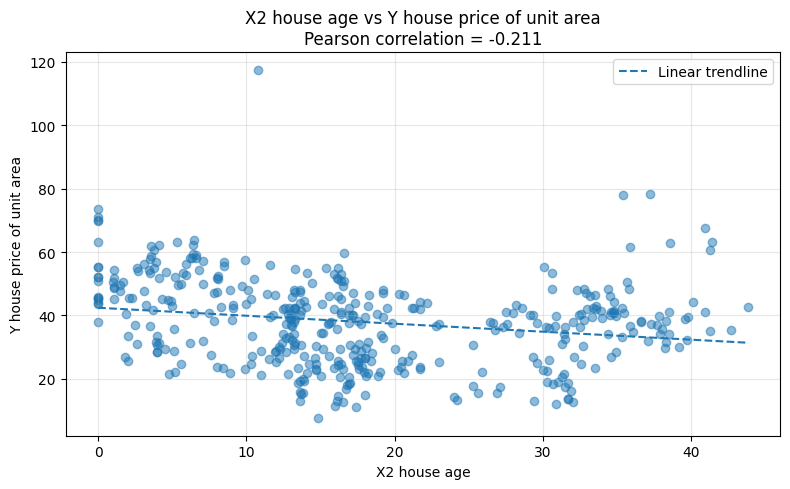

feature: X2 house age
correlation: -0.211


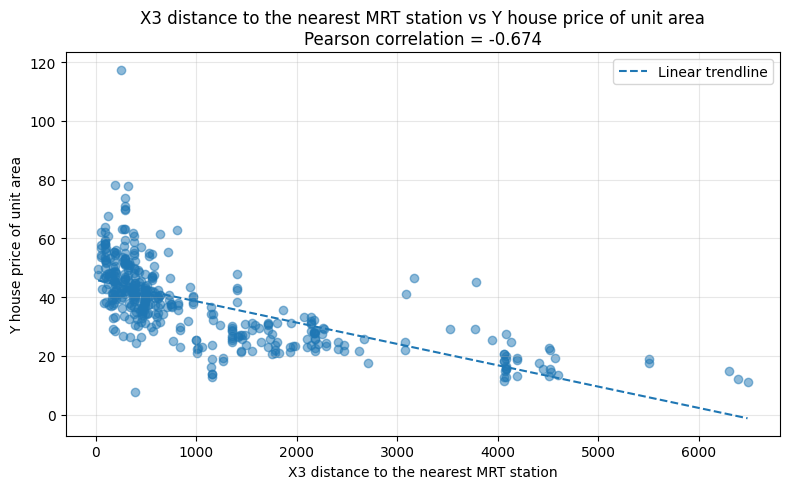

feature: X3 distance to the nearest MRT station
correlation: -0.674


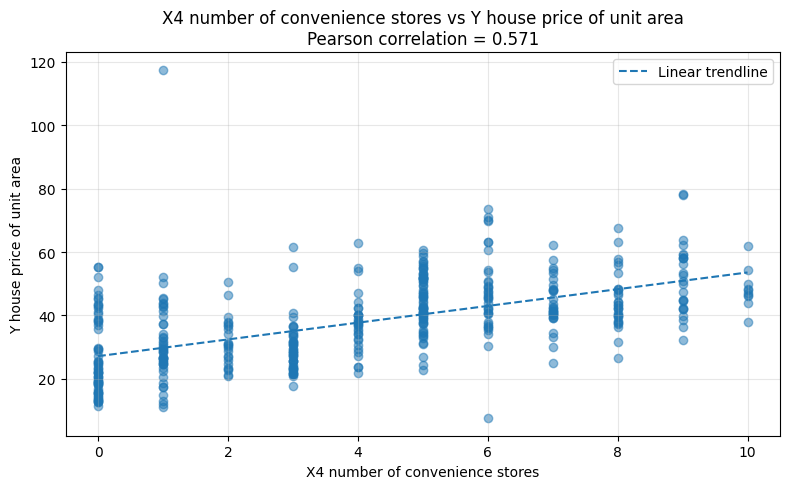

feature: X4 number of convenience stores
correlation: 0.571


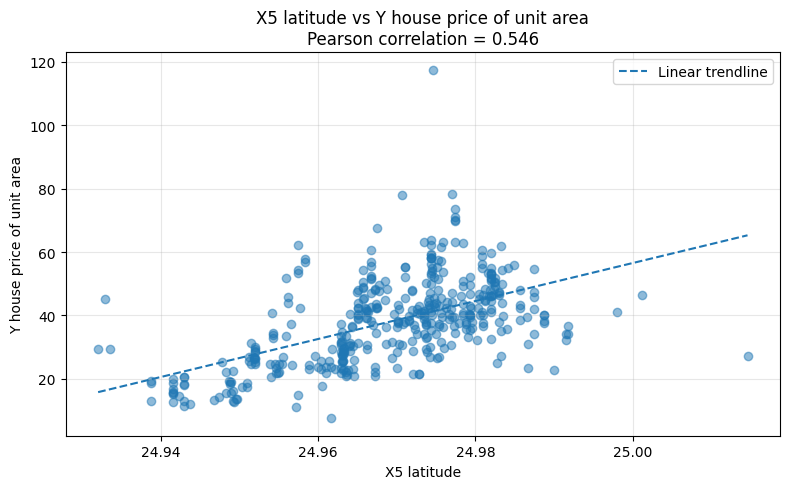

feature: X5 latitude
correlation: 0.546


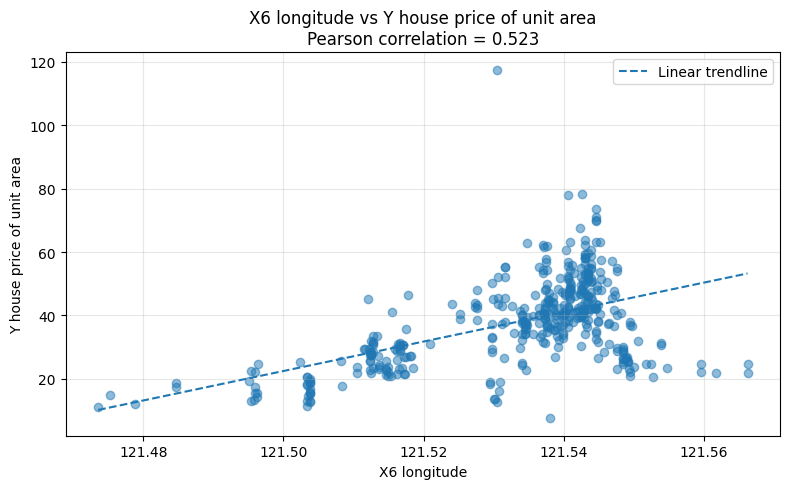

feature: X6 longitude
correlation: 0.523


In [4]:
# feature relationships analysis

relationships_results = []

for feature in numerical_features:
    x = df[feature]
    y = df[target]

    correlation = x.corr(y)

    plt.figure(figsize=(8, 5))

    plt.scatter(x, y, alpha=0.5)

    coefficients = np.polyfit(x, y, 1)

    trendline = np.poly1d(coefficients)

    x_line = np.linspace(x.min(), x.max(), 100)

    plt.plot(
        x_line,
        trendline(x_line),
        linestyle="--",
        label="Linear trendline" 
    )

    plt.title(
        f"{feature} vs {target}\n"
        f"Pearson correlation = {correlation:.3f}"
    )

    plt.xlabel(feature)
    plt.ylabel(target)

    plt.legend()
    plt.grid(alpha=0.3)
    plt.tight_layout()

    filename = f"{feature.replace(' ', '_')}_vs_target.png"
    plt.savefig(
        figures_dir/filename, 
        dpi=300, 
        bbox_inches="tight"
        )

    plt.show()
    plt.close()

    print(f"feature: {feature}")
    print(f"correlation: {correlation:.3f}")

    relationships_results.append({
        "Feature": feature,
        "Pearson Correlation": correlation
    })

relationships_summary = pd.DataFrame(relationships_results)

relationships_summary.to_csv(
    tables_dir / "feature_relationship.csv", index=False
)



X1 transaction year vs Y house price of unit area


,X1 transaction year,mean,median,count
0,2012,36.304762,37.60,126
1,2013,38.713194,39.05,288


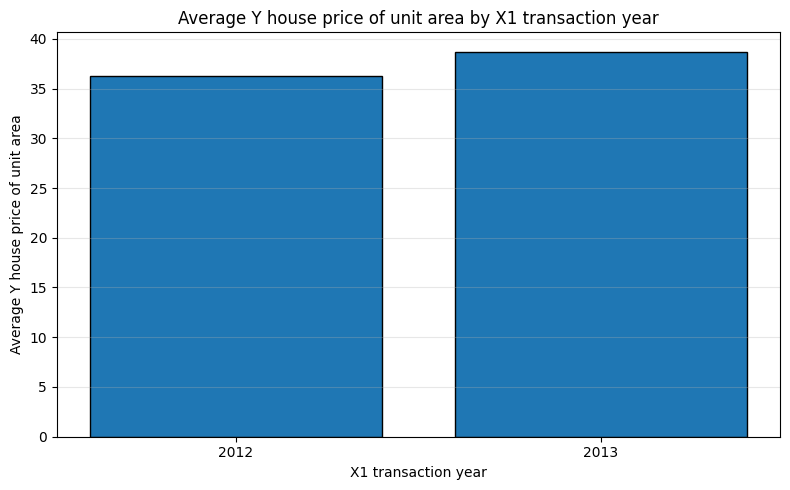


X1 transaction month vs Y house price of unit area


,X1 transaction month,mean,median,count
0,April,41.293750,41.80,32
1,August,39.604348,36.80,23
2,December,35.557895,36.80,38
3,February,40.493478,39.85,46
4,January,31.057143,33.00,28
5,July,38.119149,38.20,47
6,June,38.453448,40.05,58
7,March,38.304000,40.50,25
8,May,41.562069,41.20,29
9,November,35.683871,33.40,31


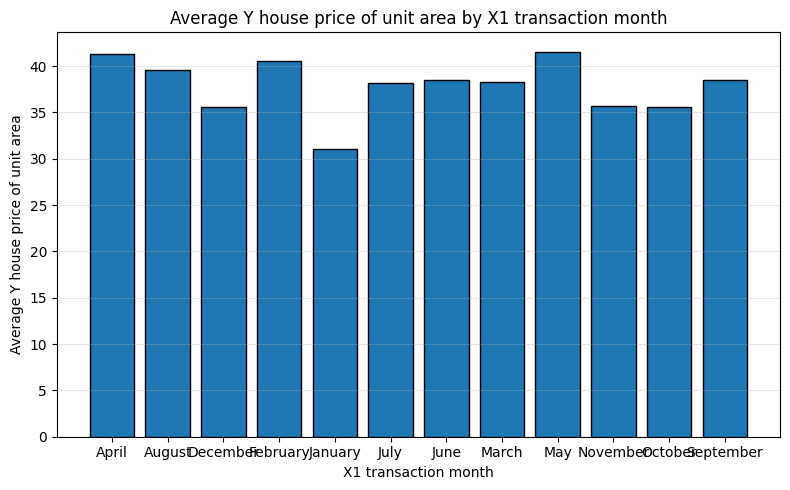

In [5]:
for feature in categorical_features:

    category_summary = (
        df.groupby(feature)[target].agg(["mean", "median", "count"]).reset_index()
    )

    print(f"\n{feature} vs {target}")
    display(category_summary)

    plt.figure(figsize=(8, 5))

    plt.bar(
        category_summary[feature].astype(str),
        category_summary["mean"],
        edgecolor = "black"
    )

    plt.title(f"Average {target} by {feature}")
    plt.xlabel(feature)
    plt.ylabel(f"Average {target}")
    plt.grid(axis="y", alpha=0.3)
    plt.tight_layout()

    plt.savefig(
        figures_dir/f"{feature.replace(' ', '_')}_vs_target.png",
        dpi = 300,
        bbox_inches = "tight"
    )

    plt.show()
    plt.close()

    category_summary.to_csv(
        tables_dir / f"{feature.replace(' ', '_')}_relationship.csv",
        index=False
    )